# ¿Qué mensajes anuncian una cancelación?
## Torneo de representaciones textuales · Sebas Padilla Lab

**Ejercicio académico de maestría (2026).** Los datos son sintéticos y de uso académico; no contienen información personal, privada ni de ninguna empresa.

**Equipo:** Juan David Gonzalez, Nelsón Fabian Manios y Sebastián Padilla Castaño.

Compara TF-IDF de palabras, caracteres y embeddings bajo una partición común, con validación agrupada por frase base.
Se ejecuta desde la carpeta `notebooks/`; lee los datos de `../datos/` y guarda las tablas en `../tablas/`.

In [1]:
import re, unicodedata, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
df=pd.read_csv('../datos/interacciones_clientes.csv'); df.head()

,id,fecha,canal,texto,categoria,prioridad,satisfaccion
0,1,2026-05-01,chat,Necesito copia de la factura de este mes,Facturación,media,5
1,2,2026-01-23,chat,La atención fue rápida y clara,Servicio,media,4
2,3,2026-04-09,correo,Quiero cancelar la suscripción,Cancelación,alta,3
3,4,2026-04-02,web,Necesito información de garantía 😕,Producto,baja,1
4,5,2026-02-20,web,Necesito hablar con una persona asesora correo...,Servicio,media,1


## 1. Auditoría

In [2]:
display(df.info()); display(df.isna().sum()); display(df.categoria.value_counts(normalize=True));
df['n_chars']=df.texto.str.len(); df.groupby('canal').n_chars.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            1200 non-null   int64
 1   fecha         1200 non-null   str  
 2   canal         1200 non-null   str  
 3   texto         1200 non-null   str  
 4   categoria     1200 non-null   str  
 5   prioridad     1200 non-null   str  
 6   satisfaccion  1200 non-null   int64
dtypes: int64(2), str(5)
memory usage: 65.8 KB


None

id              0
fecha           0
canal           0
texto           0
categoria       0
prioridad       0
satisfaccion    0
dtype: int64

categoria
Facturación    0.261667
Servicio       0.241667
Entrega        0.213333
Producto       0.187500
Cancelación    0.095833
Name: proportion, dtype: float64

,count,mean,std,min,25%,50%,75%,max
canal,,,,,,,,
chat,306.0,37.591503,11.269273,22.0,31.0,35.5,40.0,99.0
correo,314.0,36.563694,11.353347,22.0,30.0,34.0,39.0,89.0
web,290.0,36.527586,10.766519,22.0,30.0,34.0,40.0,73.0
whatsapp,290.0,36.979310,10.938626,22.0,30.0,34.0,40.0,89.0


---
# Actividad A. Auditoría y backlog de preprocesamiento

**Rol principal:** Ciencia de Datos (auditoría, fuga y errores), con aportes de ML (métricas) y Gerencia IA (riesgo).

Se registran **10 problemas o decisiones de preprocesamiento**. Para cada uno: **evidencia** (calculada abajo), **impacto**, **transformación propuesta** y **prueba A/B**.

Antes de auditar se construye una clave de *frase base* (`grupo`): el texto sin ruido (PII, URL, emojis, puntuación, mayúsculas, typos). Es la herramienta central de la auditoría porque permite ver cuántos mensajes son en realidad la misma frase.

In [3]:
import re, unicodedata, collections, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

df = pd.read_csv('../datos/interacciones_clientes.csv')
if 'texto_norm' not in df:  # por si la celda se corre sin las secciones previas
    def normalizar(s):
        s = unicodedata.normalize('NFC', str(s))
        s = re.sub(r'https?://\S+', ' URL ', s)
        s = re.sub(r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}', ' EMAIL ', s)
        return re.sub(r'\s+', ' ', s).strip()
    df['texto_norm'] = df.texto.map(normalizar)

def frase_base(s):
    s = s.lower()
    s = re.sub(r'visita https?://\S+|correo \S+@\S+', ' ', s)   # plantillas de URL / correo
    s = re.sub(r'\bx\b', 'por', s).replace('paqte', 'paquete')  # typos conocidos
    s = re.sub(r'[^\wáéíóúñü ]', ' ', s)                         # emojis y puntuación
    return re.sub(r'\s+', ' ', s).strip()

df['grupo'] = df.texto.map(frase_base)
print(f"Filas: {len(df)} | textos únicos: {df.texto.nunique()} | frases base: {df.grupo.nunique()}")
df.groupby(['categoria', 'grupo']).size().rename('n').reset_index()

Filas: 1200 | textos únicos: 219 | frases base: 20


,categoria,grupo,n
0,Cancelación,confirmen la cancelación inmediata,28
1,Cancelación,no deseo renovar el plan,28
2,Cancelación,quiero cancelar la suscripción,31
3,Cancelación,solicito terminar el servicio,28
4,Entrega,cambien la dirección de entrega,60
5,Entrega,el paquete figura entregado pero no lo recibí,56
6,Entrega,la entrega llegó incompleta,83
7,Entrega,mi pedido no ha llegado todavía,57
8,Facturación,la factura tiene un valor incorrecto,81
9,Facturación,me cobraron dos veces la factura,85


### Arnés A/B reutilizable
Cada prueba compara una variante **A** (estado actual) contra **B** (transformación propuesta) con el mismo clasificador (TF-IDF + regresión logística balanceada) y dos esquemas de evaluación:
- **Aleatorio:** la partición del laboratorio (`random_state=42`, estratificada).
- **Por grupo:** `StratifiedGroupKFold` (4 pliegues) por frase base, que obliga al modelo a clasificar frases que **no vio** en entrenamiento. Es la métrica honesta para este dataset.

Se reporta F1 macro y F1 de la clase crítica (**Cancelación**).

In [4]:
CLASE_CRITICA = 'Cancelación'

def _pipe(vect_kw, clf_kw):
    kw = dict(analyzer='word', ngram_range=(1, 2), min_df=2, sublinear_tf=True); kw.update(vect_kw or {})
    ck = dict(max_iter=1500, class_weight='balanced'); ck.update(clf_kw or {})
    return Pipeline([('tfidf', TfidfVectorizer(**kw)), ('clf', LogisticRegression(**ck))])

def evaluar(prep=None, vect_kw=None, clf_kw=None, data=None):
    d = (data if data is not None else df).copy()
    X = d.texto_norm.map(prep) if prep else d.texto_norm
    y, g = d.categoria, d.grupo
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)
    p = _pipe(vect_kw, clf_kw).fit(Xtr, ytr).predict(Xte)
    res = {'F1_aleat': f1_score(yte, p, average='macro'),
           'F1crit_aleat': f1_score(yte, p, labels=[CLASE_CRITICA], average='macro')}
    f1s, f1c = [], []
    for tr, te in StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42).split(X, y, g):
        p = _pipe(vect_kw, clf_kw).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
        f1s.append(f1_score(y.iloc[te], p, average='macro'))
        f1c.append(f1_score(y.iloc[te], p, labels=[CLASE_CRITICA], average='macro', zero_division=0))
    res.update({'F1_grupo': np.mean(f1s), 'F1crit_grupo': np.mean(f1c)})
    return res

AB = []
def ab(id_, nombre, A, B):
    """A y B son dicts con argumentos para evaluar()."""
    ra, rb = evaluar(**A), evaluar(**B)
    for var, r in (('A', ra), ('B', rb)):
        AB.append({'id': id_, 'problema': nombre, 'variante': var, **{k: round(v, 3) for k, v in r.items()}})
    return pd.DataFrame(AB[-2:])

### P1. Duplicados masivos y fuga entre train y test
**Evidencia:** 1.200 filas, pero solo ~219 textos únicos y **20 frases base** (4 por categoría). Con la partición aleatoria del laboratorio, la mayoría de los textos de test aparecen idénticos en train.

In [5]:
Xtr, Xte, ytr, yte = train_test_split(df.texto_norm, df.categoria, test_size=.25, random_state=42, stratify=df.categoria)
print(f"Test con texto idéntico en train: {Xte.isin(set(Xtr)).mean():.0%}")
print(f"Test con la misma frase base en train: {df.loc[Xte.index,'grupo'].isin(set(df.loc[Xtr.index,'grupo'])).mean():.0%}")
ab('P1', 'Partición aleatoria vs por grupo', A={}, B={})  # misma config: la diferencia está entre columnas *_aleat y *_grupo

Test con texto idéntico en train: 91%
Test con la misma frase base en train: 100%


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P1,Partición aleatoria vs por grupo,A,1.0,1.0,0.219,0.0
1,P1,Partición aleatoria vs por grupo,B,1.0,1.0,0.219,0.0


**Impacto:** F1 aleatorio ≈ 1,0 es memorización, no generalización; el torneo de la Actividad B no discriminaría entre representaciones.
**Transformación:** deduplicar para análisis, y evaluar con `StratifiedGroupKFold` por frase base (o reservar frases completas como test).
**A/B:** misma configuración evaluada con partición aleatoria (A) vs por grupo (B): comparar `F1_aleat` contra `F1_grupo`.

### P2. PII: correos de clientes con identificador
**Evidencia:** mensajes con `correo clienteN@mail.co`; el número coincide con el `id` de la fila.

In [6]:
m = df.texto.str.extract(r'cliente(\d+)@')[0].dropna().astype(int)
print(f"Mensajes con correo: {len(m)} | número == id: {(m.values == df.loc[m.index,'id'].values).mean():.0%}")
print(df.loc[m.index, 'texto'].head(3).to_list())
sin_pii = lambda s: re.sub(r'\s+', ' ', re.sub(r'correo\s+EMAIL', ' ', s)).strip()
ab('P2', 'PII: enmascarar EMAIL vs eliminar "correo EMAIL"', A={}, B={'prep': sin_pii})

Mensajes con correo: 71 | número == id: 100%
['Necesito hablar con una persona asesora correo cliente5@mail.co', 'Necesito información de garantía correo cliente34@mail.co 😕', 'la entrega llegó incompleta!!! correo cliente35@mail.co 😕']


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P2,"PII: enmascarar EMAIL vs eliminar ""correo EMAIL""",A,1.0,1.0,0.219,0.0
1,P2,"PII: enmascarar EMAIL vs eliminar ""correo EMAIL""",B,1.0,1.0,0.221,0.0


**Impacto:** riesgo de privacidad (Habeas Data, Ley 1581/2012) y fuga de identificador; el token residual `correo` además se confunde con el **canal** correo.
**Transformación:** enmascarar antes de cualquier almacenamiento o vectorización; eliminar la plantilla completa (`correo EMAIL`) y no solo la dirección.
**A/B:** `EMAIL` enmascarado (A) vs plantilla eliminada (B).

### P3. URLs de plantilla
**Evidencia:** mensajes con `visita https://ejemplo.co/caso`; tras la normalización queda `visita URL`, un bigrama constante sin relación con la categoría.

In [7]:
url = df.texto.str.contains('https?://')
print(f"Mensajes con URL: {url.sum()} | distribución por categoría:"); print(df[url].categoria.value_counts().to_dict())
sin_url = lambda s: re.sub(r'\s+', ' ', re.sub(r'(visita\s+)?\bURL\b', ' ', s)).strip()
ab('P3', 'URL: token URL vs eliminar plantilla', A={}, B={'prep': sin_url})

Mensajes con URL: 71 | distribución por categoría:
{'Servicio': 20, 'Facturación': 18, 'Entrega': 13, 'Producto': 11, 'Cancelación': 9}


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P3,URL: token URL vs eliminar plantilla,A,1.0,1.0,0.219,0.0
1,P3,URL: token URL vs eliminar plantilla,B,1.0,1.0,0.213,0.0


**Impacto:** ruido en el vocabulario y en n-gramas de caracteres (`htt`, `.co`); en producción, URLs reales podrían filtrar dominios o números de caso.
**Transformación:** eliminar la plantilla `visita <URL>` o reemplazarla por un único indicador `URL`.
**A/B:** token `URL` (A) vs plantilla eliminada (B).

### P4. Emojis y puntuación expresiva
**Evidencia:** emoji 😕 y signos repetidos (`!!!`, `??`, `...`) repartidos de forma casi uniforme entre categorías: expresan emoción, no tema.

In [8]:
emo = df.texto.str.contains('😕'); rep = df.texto.str.contains(r'[!?.]{2,}')
print(f"Con emoji: {emo.sum()} | con puntuación repetida: {rep.sum()}")
print(pd.crosstab(df.categoria, emo, normalize='index').round(2).rename(columns={False:'sin',True:'con emoji'}))
expr = lambda s: re.sub(r'\s+', ' ', re.sub(r'[!?.]{2,}', ' ', s.replace('😕', ' EMO_NEG '))).strip()
ab('P4', 'Emojis/puntuación: crudos vs EMO_NEG y signos normalizados', A={}, B={'prep': expr})

Con emoji: 100 | con puntuación repetida: 260
texto         sin  con emoji
categoria                   
Cancelación  0.90       0.10
Entrega      0.92       0.08
Facturación  0.92       0.08
Producto     0.92       0.08
Servicio     0.91       0.09


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P4,Emojis/puntuación: crudos vs EMO_NEG y signos ...,A,1.0,1.0,0.219,0.000
1,P4,Emojis/puntuación: crudos vs EMO_NEG y signos ...,B,1.0,1.0,0.227,0.042


**Impacto:** TF-IDF de palabras los ignora (el tokenizador por defecto los descarta), pero el de caracteres sí los usa; no aportan a la categoría, pero sí a prioridad o satisfacción.
**Transformación:** mapear emojis a etiquetas (`EMO_NEG`) y colapsar puntuación repetida; conservar la señal como variable aparte para tareas de urgencia.
**A/B:** texto crudo (A) vs normalizado (B), en especial con `analyzer='char_wb'`.

### P5. Mayúsculas y tildes
**Evidencia:** la misma frase aparece con y sin mayúscula inicial; el vocabulario del dominio depende de tildes (`facturación`, `cancelación`, `garantía`) y el notebook ya prueba un caso como `facturacionn`.

In [9]:
print(df[df.grupo == 'me cobraron dos veces la factura'].texto.str[:1].value_counts().to_dict())
ab('P5', 'Tildes: conservar vs strip_accents', A={}, B={'vect_kw': {'strip_accents': 'unicode'}})

{'M': 70, 'm': 15}


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P5,Tildes: conservar vs strip_accents,A,1.0,1.0,0.219,0.0
1,P5,Tildes: conservar vs strip_accents,B,1.0,1.0,0.219,0.0


**Impacto:** sin `lowercase` ni `strip_accents`, cada variante es un rasgo distinto; en canales informales (WhatsApp) los usuarios omiten tildes con frecuencia.
**Transformación:** `lowercase=True` (ya es el valor por defecto) y evaluar `strip_accents='unicode'`; aplicar la misma función en entrenamiento y en inferencia.
**A/B:** con tildes (A) vs sin tildes (B).

### P6. Errores ortográficos y abreviaturas
**Evidencia:** variantes como `x` por `por` (`no responden x el chat`) y `paqte` por `paquete`; ninguna aparece en el corpus de embeddings (OOV).

In [10]:
for pat in [r'\bx\b', r'paqte']:
    print(pat, df.texto.str.contains(pat).sum(), df[df.texto.str.contains(pat)].texto.iloc[0])
DIC = {r'\bx\b': 'por', r'\bpaqte\b': 'paquete'}
def corrige(s):
    for p, r in DIC.items(): s = re.sub(p, r, s)
    return s
ab('P6', 'Typos: sin corregir vs diccionario de normalización', A={}, B={'prep': corrige})

\bx\b 9 No responden x el chat 😕
paqte 3 El paqte figura entregado pero no lo recibí


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P6,Typos: sin corregir vs diccionario de normaliz...,A,1.0,1.0,0.219,0.000
1,P6,Typos: sin corregir vs diccionario de normaliz...,B,1.0,1.0,0.225,0.027


**Impacto:** con vocabulario de palabras, la variante mal escrita queda aislada; con `min_df=2` puede desaparecer. Los n-gramas de caracteres y fastText son más robustos a este ruido.
**Transformación:** diccionario de normalización mantenido por el equipo, o delegar la robustez a `char_wb`/fastText (se decide en la Actividad B).
**A/B:** sin corregir (A) vs con diccionario (B); repetir con `char_wb`.

### P7. Negación y stopwords
**Evidencia:** `no` aparece en un tercio de los mensajes y define el sentido: `no reconozco este cobro`, `no deseo renovar el plan`, `no ha llegado`.

In [11]:
print(f"Mensajes con 'no': {df.texto.str.contains(r'(?i)\bno\b').mean():.0%}")
print(pd.crosstab(df.categoria, df.texto.str.contains(r'(?i)\bno\b')).rename(columns={False:'sin no',True:'con no'}))
STOP_ES = ['de','la','que','el','en','y','a','los','se','del','las','un','por','con','no','una','su','para','es','al','lo','como','mi','me','este','ha']
ab('P7', "Stopwords: lista genérica (sin 'no') vs lista que conserva 'no'",
   A={'vect_kw': {'stop_words': STOP_ES}},
   B={'vect_kw': {'stop_words': [w for w in STOP_ES if w != 'no']}})

Mensajes con 'no': 35%
texto        sin no  con no
categoria                  
Cancelación      87      28
Entrega         143     113
Facturación     226      88
Producto        179      46
Servicio        144     146


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P7,Stopwords: lista genérica (sin 'no') vs lista ...,A,1.0,1.0,0.240,0.016
1,P7,Stopwords: lista genérica (sin 'no') vs lista ...,B,1.0,1.0,0.218,0.016


**Impacto:** las listas genéricas de stopwords en español eliminan `no`, lo que borra la señal de Cancelación (`no deseo renovar`) y de Facturación (`no reconozco`).
**Transformación:** no eliminar stopwords por defecto; si se usa una lista, excluir negaciones (`no`, `nunca`, `sin`) y usar bigramas (`no reconozco`).
**A/B:** lista genérica (A) vs lista que conserva la negación (B).

### P8. Desbalance y clase crítica (Cancelación)
**Evidencia:** Cancelación es la clase minoritaria y la de mayor riesgo de negocio (pérdida de cliente).

In [12]:
print(df.categoria.value_counts(normalize=True).round(3).to_dict())
ab('P8', 'Desbalance: sin pesos vs class_weight=balanced', A={'clf_kw': {'class_weight': None}}, B={})

{'Facturación': 0.262, 'Servicio': 0.242, 'Entrega': 0.213, 'Producto': 0.188, 'Cancelación': 0.096}


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P8,Desbalance: sin pesos vs class_weight=balanced,A,1.0,1.0,0.196,0.0
1,P8,Desbalance: sin pesos vs class_weight=balanced,B,1.0,1.0,0.219,0.0


**Impacto:** la exactitud y el F1 ponderado esconden errores en la clase minoritaria; un falso negativo en Cancelación implica no activar retención.
**Transformación:** partición estratificada (por grupo), `class_weight='balanced'`, y reportar F1 y recall por clase con un umbral propio para Cancelación.
**A/B:** sin pesos (A) vs balanceado (B), mirando `F1crit_*`.

### P9. Metadatos con fuga y sesgo por canal
**Evidencia:** `prioridad='alta'` solo aparece en Facturación y Cancelación; el canal está casi equilibrado entre categorías, pero tiene ruido propio (tokens de plantilla).

In [13]:
display(pd.crosstab(df.categoria, df.prioridad))
display(pd.crosstab(df.canal, df.categoria, normalize='index').round(2))
print('Satisfacción media por categoría:', df.groupby('categoria').satisfaccion.mean().round(2).to_dict())
con_prio = df.assign(texto_norm=df.prioridad + ' ' + df.texto_norm)
ab('P9', 'Metadatos: solo texto vs texto + prioridad', A={}, B={'data': con_prio})

prioridad,alta,baja,media
categoria,,,
Cancelación,66,13,36
Entrega,0,81,175
Facturación,170,46,98
Producto,0,79,146
Servicio,0,94,196


categoria,Cancelación,Entrega,Facturación,Producto,Servicio
canal,,,,,
chat,0.08,0.23,0.27,0.17,0.25
correo,0.10,0.20,0.25,0.19,0.26
web,0.10,0.22,0.28,0.17,0.24
whatsapp,0.11,0.21,0.24,0.21,0.22


Satisfacción media por categoría: {'Cancelación': 2.9, 'Entrega': 3.02, 'Facturación': 2.83, 'Producto': 2.96, 'Servicio': 2.97}


,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P9,Metadatos: solo texto vs texto + prioridad,A,1.0,1.0,0.219,0.000
1,P9,Metadatos: solo texto vs texto + prioridad,B,1.0,1.0,0.321,0.179


**Impacto:** `prioridad` probablemente se asigna **después** de leer el mensaje (variable posterior al evento); usarla infla el desempeño y no estará disponible al momento de clasificar.
**Transformación:** excluir `prioridad` y `satisfaccion` como predictores; usar `canal` solo para reportar métricas por canal (robustez), no como atajo.
**A/B:** solo texto (A) vs texto + prioridad (B). Si B mejora, se confirma la fuga y se descarta.

### P10. Corpus de embeddings contaminado
**Evidencia:** el corpus auxiliar tiene 800 líneas, pero solo **20 únicas**, y cada una termina con la **etiqueta de la categoría** + 5 tokens constantes (`cliente servicio organización proceso respuesta`). Las 20 frases son las mismas del dataset.

In [14]:
L = [l.strip() for l in open('../datos/corpus_embeddings.txt', encoding='utf-8') if l.strip()]
print(f"Líneas: {len(L)} | únicas: {len(set(L))}")
print('Sufijos:', collections.Counter(' '.join(l.split()[-6:]) for l in L).most_common(5))
core = {' '.join(l.split()[:-6]) for l in L}
print(f"Frases base del dataset presentes en el corpus: {sum(g in core for g in df.grupo.unique())}/{df.grupo.nunique()}")
vocab_corpus = {w for l in L for w in l.split()}
tokens_ds = {w for t in df.texto_norm.str.lower() for w in re.findall(r'[a-záéíóúñü]+', t)} - {'email', 'url'}
oov = sorted(w for w in tokens_ds if w not in vocab_corpus)
print('OOV del dataset (sin PII):', oov)

Líneas: 800 | únicas: 20
Sufijos: [('facturación cliente servicio organización proceso respuesta', 160), ('entrega cliente servicio organización proceso respuesta', 160), ('producto cliente servicio organización proceso respuesta', 160), ('servicio cliente servicio organización proceso respuesta', 160), ('cancelación cliente servicio organización proceso respuesta', 160)]
Frases base del dataset presentes en el corpus: 20/20
OOV del dataset (sin PII): ['correo', 'paqte', 'visita', 'x']


**Impacto:** Word2Vec aprenderá que `facturación` es vecino de las frases de facturación porque **la etiqueta está pegada al texto** (fuga de etiqueta); los 5 tokens constantes dominan las coocurrencias y las 20 frases repetidas dejan un espacio vectorial pobre.
**Transformación:** eliminar el sufijo (etiqueta + tokens constantes), deduplicar, excluir las frases de test y ampliar el corpus con texto del dominio sin etiquetar.
**A/B (para la Actividad C):** entrenar Word2Vec/fastText con corpus original (A) vs limpio (B) y comparar vecinos de `factura`, `cobro`, `cancelar`, cobertura OOV y F1 por grupo del promedio de vectores.

## Backlog de preprocesamiento (resumen)
Tabla lista para la matriz comparativa y la ficha ejecutiva. Prioridad: **Alta** = invalida la evaluación o genera riesgo legal; **Media** = afecta robustez; **Baja** = ajuste fino.

In [15]:
backlog = pd.DataFrame([
 ['P1','Duplicados masivos y fuga train/test','~219 textos únicos y 20 frases base; >90% del test idéntico en train','F1 inflado (≈1,0); el torneo no discrimina','Deduplicar + StratifiedGroupKFold por frase base','Partición aleatoria vs por grupo','Alta','ML / Ciencia de Datos'],
 ['P2','PII: correo con ID de cliente','Correos clienteN@mail.co; N = id','Riesgo legal (Ley 1581) y fuga de identificador','Eliminar plantilla "correo EMAIL" antes de guardar o vectorizar','EMAIL enmascarado vs plantilla eliminada','Alta','Gerencia IA / Ciencia de Datos'],
 ['P3','URLs de plantilla','"visita https://ejemplo.co/caso" → "visita URL"','Ruido en vocabulario y n-gramas de caracteres','Eliminar plantilla o token único URL','Token URL vs eliminación','Media','Ciencia de Datos'],
 ['P4','Emojis y puntuación expresiva','😕 y !!!/??/... uniformes entre clases','Ruido para categoría; señal útil para urgencia','EMO_NEG + colapsar signos; guardar como variable aparte','Crudo vs normalizado (word y char)','Baja','ML'],
 ['P5','Mayúsculas y tildes','Variantes de capitalización; términos con tilde','Fragmentación del vocabulario','lowercase + evaluar strip_accents','Con vs sin tildes','Media','ML'],
 ['P6','Errores y abreviaturas','"x"→por, "paqte"; OOV en corpus','Rasgos aislados o perdidos con min_df','Diccionario de normalización o char_wb/fastText','Sin vs con diccionario','Media','Ciencia de Datos'],
 ['P7','Negación y stopwords','"no" en ~1/3 de mensajes; define el sentido','Pérdida de señal en Cancelación/Facturación','No quitar negaciones; bigramas','Stopwords genéricas vs conservando "no"','Alta','ML'],
 ['P8','Desbalance (Cancelación)','Clase minoritaria y de mayor costo','Falsos negativos en retención','Estratificar, class_weight, F1/recall por clase y umbral propio','Sin pesos vs balanced','Alta','ML / Gerencia IA'],
 ['P9','Metadatos con fuga y canal','prioridad=alta solo en Facturación/Cancelación','Desempeño inflado, no disponible en inferencia','Excluir prioridad/satisfacción; reportar por canal','Texto vs texto + prioridad','Alta','Ciencia de Datos / Gerencia IA'],
 ['P10','Corpus de embeddings contaminado','800 líneas, 20 únicas, etiqueta pegada al final','Fuga de etiqueta y vecinos triviales','Quitar sufijo, deduplicar, excluir test, ampliar corpus','Corpus original vs limpio (Act. C)','Alta','Ciencia de Datos'],
], columns=['id','problema','evidencia','impacto','transformacion','prueba_AB','prioridad','responsable'])
backlog

,id,problema,evidencia,impacto,transformacion,prueba_AB,prioridad,responsable
0,P1,Duplicados masivos y fuga train/test,~219 textos únicos y 20 frases base; >90% del ...,"F1 inflado (≈1,0); el torneo no discrimina",Deduplicar + StratifiedGroupKFold por frase base,Partición aleatoria vs por grupo,Alta,ML / Ciencia de Datos
1,P2,PII: correo con ID de cliente,Correos clienteN@mail.co; N = id,Riesgo legal (Ley 1581) y fuga de identificador,"Eliminar plantilla ""correo EMAIL"" antes de gua...",EMAIL enmascarado vs plantilla eliminada,Alta,Gerencia IA / Ciencia de Datos
2,P3,URLs de plantilla,"""visita https://ejemplo.co/caso"" → ""visita URL""",Ruido en vocabulario y n-gramas de caracteres,Eliminar plantilla o token único URL,Token URL vs eliminación,Media,Ciencia de Datos
3,P4,Emojis y puntuación expresiva,😕 y !!!/??/... uniformes entre clases,Ruido para categoría; señal útil para urgencia,EMO_NEG + colapsar signos; guardar como variab...,Crudo vs normalizado (word y char),Baja,ML
4,P5,Mayúsculas y tildes,Variantes de capitalización; términos con tilde,Fragmentación del vocabulario,lowercase + evaluar strip_accents,Con vs sin tildes,Media,ML
5,P6,Errores y abreviaturas,"""x""→por, ""paqte""; OOV en corpus",Rasgos aislados o perdidos con min_df,Diccionario de normalización o char_wb/fastText,Sin vs con diccionario,Media,Ciencia de Datos
6,P7,Negación y stopwords,"""no"" en ~1/3 de mensajes; define el sentido",Pérdida de señal en Cancelación/Facturación,No quitar negaciones; bigramas,"Stopwords genéricas vs conservando ""no""",Alta,ML
7,P8,Desbalance (Cancelación),Clase minoritaria y de mayor costo,Falsos negativos en retención,"Estratificar, class_weight, F1/recall por clas...",Sin pesos vs balanced,Alta,ML / Gerencia IA
8,P9,Metadatos con fuga y canal,prioridad=alta solo en Facturación/Cancelación,"Desempeño inflado, no disponible en inferencia",Excluir prioridad/satisfacción; reportar por c...,Texto vs texto + prioridad,Alta,Ciencia de Datos / Gerencia IA
9,P10,Corpus de embeddings contaminado,"800 líneas, 20 únicas, etiqueta pegada al final",Fuga de etiqueta y vecinos triviales,"Quitar sufijo, deduplicar, excluir test, ampli...",Corpus original vs limpio (Act. C),Alta,Ciencia de Datos


### Resultados de las pruebas A/B
`*_aleat` = partición aleatoria del laboratorio; `*_grupo` = validación por frase base (4 pliegues). La columna relevante para decidir es **F1_grupo**.

In [16]:
res_ab = pd.DataFrame(AB)
display(res_ab)
res_ab.to_csv('../tablas/resultados_pruebas_ab.csv', index=False)
backlog.to_csv('../tablas/backlog_auditoria.csv', index=False)
print('Guardados: tablas/backlog_auditoria.csv y tablas/resultados_pruebas_ab.csv')

,id,problema,variante,F1_aleat,F1crit_aleat,F1_grupo,F1crit_grupo
0,P1,Partición aleatoria vs por grupo,A,1.0,1.0,0.219,0.000
1,P1,Partición aleatoria vs por grupo,B,1.0,1.0,0.219,0.000
2,P2,"PII: enmascarar EMAIL vs eliminar ""correo EMAIL""",A,1.0,1.0,0.219,0.000
3,P2,"PII: enmascarar EMAIL vs eliminar ""correo EMAIL""",B,1.0,1.0,0.221,0.000
4,P3,URL: token URL vs eliminar plantilla,A,1.0,1.0,0.219,0.000
5,P3,URL: token URL vs eliminar plantilla,B,1.0,1.0,0.213,0.000
6,P4,Emojis/puntuación: crudos vs EMO_NEG y signos ...,A,1.0,1.0,0.219,0.000
7,P4,Emojis/puntuación: crudos vs EMO_NEG y signos ...,B,1.0,1.0,0.227,0.042
8,P5,Tildes: conservar vs strip_accents,A,1.0,1.0,0.219,0.000
9,P5,Tildes: conservar vs strip_accents,B,1.0,1.0,0.219,0.000


Guardados: tablas/backlog_auditoria.csv y tablas/resultados_pruebas_ab.csv


### Lectura de resultados (para el comité)
- **La fuga es el hallazgo dominante (P1).** Con la partición aleatoria todas las variantes obtienen F1 = 1,0; con validación por frase base el F1 macro cae a ≈ 0,2 y Cancelación queda en ≈ 0. Ninguna decisión de las Actividades B y C debe tomarse con la partición aleatoria.
- **P9 confirma una fuga por metadatos:** agregar `prioridad` sube el F1 por grupo (≈ 0,22 → ≈ 0,32) y el de Cancelación, justo porque `alta` solo ocurre en Facturación y Cancelación. Esa mejora es artificial: se excluye `prioridad`.
- **Las transformaciones de limpieza (P2–P6) mueven el F1 por grupo menos de ±0,01.** Con 20 frases base, esas diferencias están dentro del ruido; se justifican por privacidad, robustez y consistencia en producción, no por la métrica.
- **P7 no muestra ventaja en este dataset** para conservar `no`; aun así se mantiene la regla, porque en frases nuevas la negación invierte el sentido. Hay que volver a evaluarlo con más datos.
- **Siguiente paso:** pedir más frases reales por categoría (sobre todo Cancelación) antes del torneo. Con 4 frases por clase, ninguna representación puede generalizar de forma confiable.

## 2. Normalización mínima y enmascaramiento

In [17]:
def normalizar(s):
    s=unicodedata.normalize('NFC',str(s))
    s=re.sub(r'https?://\S+',' URL ',s)
    s=re.sub(r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}',' EMAIL ',s)
    s=re.sub(r'\s+',' ',s).strip()
    return s
df['texto_norm']=df.texto.map(normalizar)
df[['texto','texto_norm']].head()

,texto,texto_norm
0,Necesito copia de la factura de este mes,Necesito copia de la factura de este mes
1,La atención fue rápida y clara,La atención fue rápida y clara
2,Quiero cancelar la suscripción,Quiero cancelar la suscripción
3,Necesito información de garantía 😕,Necesito información de garantía 😕
4,Necesito hablar con una persona asesora correo...,Necesito hablar con una persona asesora correo...


## 3. Partición común

In [18]:
Xtr,Xte,ytr,yte=train_test_split(df.texto_norm,df.categoria,test_size=.25,random_state=42,stratify=df.categoria)

## 4. Torneo: palabras vs caracteres

In [19]:
pipelines={
'word_12':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('clf',LogisticRegression(max_iter=1500,class_weight='balanced'))]),
'char_35':Pipeline([('tfidf',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,sublinear_tf=True)),('clf',LogisticRegression(max_iter=1500,class_weight='balanced'))])}
resultados=[]
for nombre,m in pipelines.items():
 t=time.perf_counter();m.fit(Xtr,ytr);pred=m.predict(Xte);
 resultados.append([nombre,f1_score(yte,pred,average='macro'),time.perf_counter()-t,m.named_steps['tfidf'].get_feature_names_out().size])
pd.DataFrame(resultados,columns=['modelo','f1_macro','segundos','n_features'])

,modelo,f1_macro,segundos,n_features
0,word_12,1.0,0.025439,201
1,char_35,1.0,0.066125,1285


## 5. Evaluación del campeón

              precision    recall  f1-score   support

 Cancelación       1.00      1.00      1.00        29
     Entrega       1.00      1.00      1.00        64
 Facturación       1.00      1.00      1.00        79
    Producto       1.00      1.00      1.00        56
    Servicio       1.00      1.00      1.00        72

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



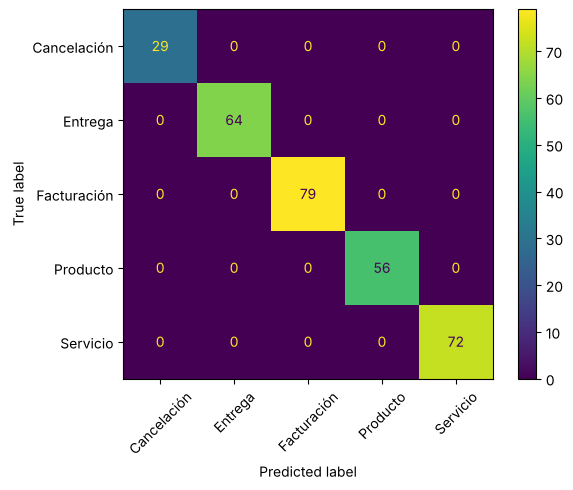

In [20]:
champ=pipelines[max(resultados,key=lambda x:x[1])[0]]
pred=champ.predict(Xte)
print(classification_report(yte,pred))
ConfusionMatrixDisplay.from_predictions(yte,pred,xticks_rotation=45)

## 6. Embeddings con Gensim (opcional si está instalado)

In [21]:
#%pip install gensim
# Paso opcional: si gensim no está instalado, se omite y la Actividad C usa la implementación de respaldo en numpy.
try:
    from gensim.models import Word2Vec, FastText
    sentences=[line.strip().split() for line in open('../datos/corpus_embeddings.txt',encoding='utf-8') if line.strip()]
    w2v=Word2Vec(sentences=sentences,vector_size=50,window=5,min_count=1,workers=1,epochs=30,seed=42)
    ft=FastText(sentences=sentences,vector_size=50,window=5,min_count=1,workers=1,epochs=30,seed=42)
    display(w2v.wv.most_similar('facturación',topn=5), ft.wv['facturacionn'][:5])
except ImportError:
    print('gensim no está instalado: se omite este paso opcional. Ver la Actividad C (implementación de respaldo en numpy).')

gensim no está instalado: se omite este paso opcional. Ver la Actividad C (implementación de respaldo en numpy).


## 7. Decisión por roles
Complete la matriz comparativa y redacte una recomendación condicionada.

---
# Actividad B. Torneo disperso

**Rol principal:** ML.

Se comparan cuatro representaciones TF-IDF con el mismo clasificador (regresión logística balanceada) y **la misma partición para todas**: los 4 pliegues de `StratifiedGroupKFold` por frase base del arnés de la Actividad A. La partición aleatoria no se usa porque le da F1 = 1,0 a todo (P1).

**Entrada:** `texto_limpio`, que aplica el backlog de la Actividad A (sin la plantilla de correo con PII, sin URL, emojis como `EMO_NEG`, typos corregidos). `prioridad` y `satisfaccion` quedan fuera (P9).

| Variante | Representación |
|---|---|
| TF-IDF palabras | unigramas + bigramas |
| TF-IDF caracteres | n-gramas `char_wb` de 3 a 5 |
| TF-IDF lemas | palabras lematizadas (diccionario + regla de plural; spaCy no está instalado) |
| TF-IDF palabras + caracteres | unión de ambas (variante de n-gramas) |

Además del F1 macro y el F1 de Cancelación se registran la dispersión entre pliegues, el F1 del peor canal, el tiempo, el número de rasgos y el tamaño del modelo, que son las columnas de la matriz comparativa.

In [22]:
import time, pickle
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import classification_report

limpiar = lambda s: corrige(expr(sin_url(sin_pii(s))))
df['texto_limpio'] = df.texto_norm.map(limpiar)

# Lematización por diccionario + regla de plural (spaCy no está disponible en el entorno).
# Verbos al infinitivo; adjetivos y artículos al masculino singular.
LEMAS = {'cobraron': 'cobrar', 'confirmen': 'confirmar', 'cambien': 'cambiar', 'dejó': 'dejar', 'deseo': 'desear',
         'entregado': 'entregar', 'llegado': 'llegar', 'llegó': 'llegar', 'recibida': 'recibir', 'recibí': 'recibir',
         'reconozco': 'reconocer', 'responden': 'responder', 'quiero': 'querer', 'solicito': 'solicitar',
         'necesito': 'necesitar', 'permite': 'permitir', 'tiene': 'tener', 'fue': 'ser', 'figura': 'figurar',
         'corresponde': 'corresponder', 'ha': 'haber', 'veces': 'vez', 'incompleta': 'incompleto',
         'inmediata': 'inmediato', 'clara': 'claro', 'rápida': 'rápido', 'una': 'uno', 'un': 'uno', 'la': 'el'}
def lematizar(s):
    return ' '.join(LEMAS.get(t, re.sub(r'(?<=\w{3})s$', '', t)) for t in re.findall(r'\w+', s.lower()))
df['texto_lema'] = df.texto_limpio.map(lematizar)
display(df[['texto_limpio', 'texto_lema']].drop_duplicates('texto_lema').head(6))

# Partición común para B y C: los mismos 4 pliegues por frase base del arnés de la Actividad A
y = df.categoria
CV = list(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42).split(df, y, df.grupo))
CLASES = sorted(y.unique())

def torneo(nombre, make_model, X):
    """Evalúa make_model() en los pliegues comunes. Guarda probabilidades fuera de pliegue para la Actividad D."""
    oof, f1s, f1c = np.zeros((len(X), len(CLASES))), [], []
    t0 = time.perf_counter()
    for tr, te in CV:
        m = make_model().fit(X.iloc[tr], y.iloc[tr])
        oof[te] = m.predict_proba(X.iloc[te])
        p = m.predict(X.iloc[te])
        f1s.append(f1_score(y.iloc[te], p, average='macro'))
        f1c.append(f1_score(y.iloc[te], p, labels=[CLASE_CRITICA], average='macro', zero_division=0))
    seg = time.perf_counter() - t0
    m = make_model().fit(X, y)  # modelo final: tamaño y n.º de rasgos
    pred = np.array(CLASES)[oof.argmax(1)]
    f1_canal = {c: f1_score(y[df.canal == c], pred[df.canal == c], average='macro') for c in sorted(df.canal.unique())}
    return {'representacion': nombre, 'F1_grupo': np.mean(f1s), 'F1crit_grupo': np.mean(f1c),
            'F1_pliegue_min': np.min(f1s), 'F1_pliegue_max': np.max(f1s),
            'F1_peor_canal': min(f1_canal.values()), 'segundos': seg,
            'n_features': m[:-1].transform(X.iloc[:1]).shape[1], 'memoria_KB': len(pickle.dumps(m)) / 1024,
            'oof': oof, 'f1_canal': f1_canal}

,texto_limpio,texto_lema
0,Necesito copia de la factura de este mes,necesitar copia de el factura de este mes
1,La atención fue rápida y clara,el atención ser rápido y claro
2,Quiero cancelar la suscripción,querer cancelar el suscripción
3,Necesito información de garantía EMO_NEG,necesitar información de garantía emo_neg
4,Necesito hablar con una persona asesora,necesitar hablar con uno persona asesora
5,La aplicación no permite iniciar sesión,el aplicación no permitir iniciar sesión


In [23]:
def tfidf(**kw):
    base = dict(analyzer='word', ngram_range=(1, 2), min_df=2, sublinear_tf=True); base.update(kw)
    return TfidfVectorizer(**base)
clf = lambda: LogisticRegression(max_iter=1500, class_weight='balanced')

modelos_B = {
    'TF-IDF palabras': (lambda: Pipeline([('vec', tfidf()), ('clf', clf())]), df.texto_limpio),
    'TF-IDF caracteres': (lambda: Pipeline([('vec', tfidf(analyzer='char_wb', ngram_range=(3, 5))), ('clf', clf())]), df.texto_limpio),
    'TF-IDF lemas': (lambda: Pipeline([('vec', tfidf()), ('clf', clf())]), df.texto_lema),
    'TF-IDF palabras + caracteres': (lambda: Pipeline([('vec', FeatureUnion([('w', tfidf()), ('c', tfidf(analyzer='char_wb', ngram_range=(3, 5)))])),
                                                       ('clf', clf())]), df.texto_limpio),
}
RES = {n: torneo(n, mk, X) for n, (mk, X) in modelos_B.items()}
COLS = ['representacion', 'F1_grupo', 'F1crit_grupo', 'F1_pliegue_min', 'F1_pliegue_max', 'F1_peor_canal', 'segundos', 'n_features', 'memoria_KB']
tabla_B = pd.DataFrame([RES[n] for n in modelos_B])[COLS].sort_values('F1_grupo', ascending=False).round(3)
tabla_B

,representacion,F1_grupo,F1crit_grupo,F1_pliegue_min,F1_pliegue_max,F1_peor_canal,segundos,n_features,memoria_KB
3,TF-IDF palabras + caracteres,0.471,0.500,0.321,0.600,0.478,0.274,1141,67.038
1,TF-IDF caracteres,0.466,0.500,0.321,0.600,0.409,0.260,961,55.662
2,TF-IDF lemas,0.311,0.125,0.155,0.524,0.310,0.102,176,12.274
0,TF-IDF palabras,0.211,0.000,0.000,0.349,0.208,0.119,180,12.490


In [24]:
mejor_B = tabla_B.representacion.iloc[0]
pred_B = np.array(CLASES)[RES[mejor_B]['oof'].argmax(1)]
print(f'Mejor representación dispersa: {mejor_B}\n')
print(classification_report(y, pred_B, zero_division=0))
pd.crosstab(y, pred_B, rownames=['real'], colnames=['predicho'])

Mejor representación dispersa: TF-IDF palabras + caracteres

              precision    recall  f1-score   support

 Cancelación       0.45      0.51      0.48       115
     Entrega       0.73      0.78      0.75       256
 Facturación       1.00      1.00      1.00       314
    Producto       0.17      0.22      0.19       225
    Servicio       0.00      0.00      0.00       290

    accuracy                           0.52      1200
   macro avg       0.47      0.50      0.49      1200
weighted avg       0.49      0.52      0.50      1200



predicho,Cancelación,Entrega,Facturación,Producto,Servicio
real,,,,,
Cancelación,59,0,0,24,32
Entrega,0,199,0,0,57
Facturación,0,0,314,0,0
Producto,0,73,0,50,102
Servicio,73,0,0,217,0


### Lectura del torneo disperso
- **Los caracteres más que duplican a las palabras** (F1 ≈ 0,47 frente a 0,21). Con 15 frases de entrenamiento por pliegue, casi ninguna palabra de una frase nueva se vio antes en su categoría. Los n-gramas de caracteres sí conectan formas de la misma raíz: `cancel` en *cancelar*/*cancelación*, `cobr` en *cobro*/*cobraron*, `entreg` en *entrega*/*entregado*.
- **La lematización ayuda (0,21 → 0,31)** por la misma razón, pero menos: une flexiones (*llegó*/*llegado* → *llegar*), no derivaciones (*cancelar* ≠ *cancelación*).
- **Palabras + caracteres no mejora a caracteres solos** (0,471 frente a 0,466). La diferencia es mucho menor que la variación entre pliegues (0,32–0,60).
- **El desempeño es muy desigual por clase:** Facturación queda perfecta (sus frases comparten *factura* y *cobr*), Entrega es aceptable (≈ 0,75), Producto queda en ≈ 0,2 y Servicio en 0: sus frases (*chat*, *sesión*, *asesora*, *atención*) no comparten raíces entre sí.
- Con F1 ≈ 0,47 para 5 clases, ninguna representación está lista para operar sola.

---
# Actividad C. Embeddings

**Rol principal:** Ciencia de Datos.

Se entrenan Word2Vec y fastText (skip-gram, 50 dimensiones, ventana 5) con dos corpus:
- **Original:** el corpus auxiliar tal como se entregó (800 líneas, 20 únicas, con la etiqueta y 5 tokens constantes al final; ver P10).
- **Limpio:** sin ese sufijo y deduplicado. Para **evaluar**, los vectores se reentrenan en cada pliegue **solo con los textos de entrenamiento** de ese pliegue, así ninguna frase de prueba entra al corpus. Para **explorar** los vecinos se usa un modelo con las 20 frases limpias y los textos del dataset.

Se usa gensim si está instalado. Si no lo está (gensim aún no publica una versión precompilada para Python 3.14 en Windows), la celda usa una implementación compacta en numpy del mismo algoritmo: skip-gram con muestreo negativo y, para fastText, n-gramas de caracteres de 3 a 5. Los números exactos cambian entre una y otra; las conclusiones no.

Cada documento se representa como el **promedio** de los vectores de sus palabras y se clasifica con la misma regresión logística y los mismos pliegues de la Actividad B.

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
try:
    from gensim.models import Word2Vec, FastText
    GENSIM = True
except ImportError:
    GENSIM = False
print('gensim disponible:', GENSIM)

class SGNS:
    """Skip-gram con muestreo negativo en numpy, de respaldo si gensim no se puede instalar.
    Con subword=True cada palabra es la suma de sus n-gramas de caracteres, como en fastText,
    y una palabra OOV se representa con los n-gramas que sí conoce."""
    def __init__(self, sentences, vector_size=50, window=5, negative=5, epochs=30, alpha=0.025,
                 subword=False, min_n=3, max_n=5, seed=42):
        rng = np.random.default_rng(seed)
        cnt = collections.Counter(w for s in sentences for w in s)
        self.index_to_key = sorted(cnt, key=lambda w: -cnt[w])
        self.key_to_index = {w: i for i, w in enumerate(self.index_to_key)}
        self.vector_size, self.subword, self.min_n, self.max_n = vector_size, subword, min_n, max_n
        V, self.ngram_index = len(self.index_to_key), {}
        unidades = [[i] for i in range(V)]
        if subword:
            for i, w in enumerate(self.index_to_key):
                unidades[i] += [V + self.ngram_index.setdefault(g, len(self.ngram_index)) for g in self._ngramas(w)]
        self.W_in = (rng.random((V + len(self.ngram_index), vector_size)) - .5) / vector_size
        W_out = np.zeros((V, vector_size))
        p = np.array([cnt[w] for w in self.index_to_key]) ** .75
        tabla_neg = rng.choice(V, 100_000, p=p / p.sum())
        sents = [[self.key_to_index[w] for w in s] for s in sentences]
        total, paso = epochs * len(sents), 0
        for _ in range(epochs):
            for s in sents:
                lr = alpha * max(1 - paso / total, 1e-4); paso += 1
                for pos, c in enumerate(s):
                    b = rng.integers(1, window + 1)
                    ctx = s[max(0, pos - b):pos] + s[pos + 1:pos + 1 + b]
                    if not ctx: continue
                    ids = unidades[c]
                    h = self.W_in[ids].mean(0)
                    tgt = np.r_[ctx, tabla_neg[rng.integers(0, len(tabla_neg), len(ctx) * negative)]]
                    lab = np.r_[np.ones(len(ctx)), np.zeros(len(ctx) * negative)]
                    g = (lab - 1 / (1 + np.exp(-W_out[tgt] @ h))) * lr
                    dh = g @ W_out[tgt]
                    np.add.at(W_out, tgt, np.outer(g, h))
                    self.W_in[ids] += dh
        self.vectors = np.vstack([self.W_in[u].mean(0) for u in unidades])

    def _ngramas(self, w):
        w = f'<{w}>'
        return [w[i:i + n] for n in range(self.min_n, self.max_n + 1) for i in range(len(w) - n + 1)]

    def __getitem__(self, w):
        if w in self.key_to_index:
            return self.vectors[self.key_to_index[w]]
        ids = [len(self.index_to_key) + self.ngram_index[g] for g in self._ngramas(w) if g in self.ngram_index] if self.subword else []
        if not ids:
            raise KeyError(f"'{w}' no está en el vocabulario")
        return self.W_in[ids].mean(0)

    def most_similar(self, w, topn=5):
        v = self[w]
        M = self.vectors / np.linalg.norm(self.vectors, axis=1, keepdims=True)
        sims = M @ (v / np.linalg.norm(v))
        orden = [i for i in np.argsort(-sims) if self.index_to_key[i] != w][:topn]
        return [(self.index_to_key[i], float(sims[i])) for i in orden]

def entrenar(sentences, tipo, epochs=30):
    """Devuelve los vectores (KeyedVectors) de Word2Vec o fastText."""
    if GENSIM:
        if tipo == 'fasttext':
            return FastText(sentences=sentences, vector_size=50, window=5, min_count=1, min_n=3, max_n=5, bucket=20_000,
                            workers=1, epochs=epochs, seed=42).wv
        return Word2Vec(sentences=sentences, vector_size=50, window=5, min_count=1, workers=1, epochs=epochs, seed=42).wv
    return SGNS(sentences, epochs=epochs, subword=(tipo == 'fasttext'))

tok = lambda s: re.findall(r'\w+', s.lower())

# Corpus original (tal como se entregó) y corpus limpio: sin el sufijo etiqueta + 5 tokens constantes, deduplicado
corpus_orig = [l.split() for l in L]
corpus_limpio = sorted({tuple(l.split()[:-6]) for l in L})
print(f'Corpus original: {len(corpus_orig)} líneas | limpio: {len(corpus_limpio)} frases únicas')

t0 = time.perf_counter()
exploracion = [list(s) for s in corpus_limpio] + [tok(t) for t in df.texto_limpio.unique()]
kv = {('Word2Vec', 'original'): entrenar(corpus_orig, 'word2vec'),
      ('fastText', 'original'): entrenar(corpus_orig, 'fasttext'),
      # Solo para explorar el espacio; para evaluar se reentrena por pliegue más abajo
      ('Word2Vec', 'limpio'): entrenar(exploracion, 'word2vec', epochs=100),
      ('fastText', 'limpio'): entrenar(exploracion, 'fasttext', epochs=100)}
print(f'Entrenamiento: {time.perf_counter() - t0:.1f} s')

gensim disponible: False
Corpus original: 800 líneas | limpio: 20 frases únicas
Entrenamiento: 46.5 s


In [26]:
TERMINOS = ['factura', 'cobro', 'cancelar', 'entrega', 'garantía', 'servicio']
vecinos = pd.DataFrame({f'{m} ({c})': [', '.join(w for w, _ in v.most_similar(t, topn=4)) if t in v.key_to_index else 'OOV'
                                       for t in TERMINOS] for (m, c), v in kv.items()}, index=TERMINOS)
display(vecinos)

# Cobertura OOV: tokens del dataset que el vocabulario de cada modelo no contiene
tokens = [w for t in df.texto_limpio for w in tok(t)]
tipos = sorted(set(tokens))
for (m, c), v in kv.items():
    oov = [w for w in tipos if w not in v.key_to_index]
    print(f'{m} ({c}): cobertura de tokens {np.mean([w in v.key_to_index for w in tokens]):.1%} | tipos OOV: {oov}')

# Palabras con ruido o variantes que nunca se vieron: Word2Vec no las puede representar, fastText usa sus n-gramas
for w in ['facturacionn', 'paqte', 'cancelacion', 'reembolso']:
    for m in ['Word2Vec', 'fastText']:
        try:
            print(f"{w:>13} | {m:8} (original): {[x for x, _ in kv[(m, 'original')].most_similar(w, topn=3)]}")
        except KeyError:
            print(f'{w:>13} | {m:8} (original): OOV, sin vector')

,Word2Vec (original),fastText (original),Word2Vec (limpio),fastText (limpio)
factura,"incorrecto, valor, tiene, un","valor, un, facturación, tiene","mes, incorrecto, copia, me","mes, me, copia, incorrecto"
cobro,"en, reconozco, cuenta, mi","en, reconozco, mi, cuenta","en, reconozco, cuenta, mi","reconozco, cuenta, mi, en"
cancelar,"quiero, suscripción, confirmen, inmediata","suscripción, quiero, cancelación, confirmen","suscripción, quiero, confirmen, inmediata","cancelación, suscripción, quiero, inmediata"
entrega,"incompleta, cambien, dirección, todavía","incompleta, todavía, lo, cambien","incompleta, cambien, dirección, averiado","cambien, incompleta, dirección, entregado"
garantía,"información, funcionar, averiado, dejó","funcionar, información, averiado, producto","información, copia, necesito, funcionar","información, copia, necesito, funcionar"
servicio,"respuesta, proceso, responden, organización","respuesta, proceso, solicito, organización","terminar, solicito, averiado, artículo","solicito, terminar, funcionar, plan"


Word2Vec (original): cobertura de tokens 98.5% | tipos OOV: ['emo_neg']
fastText (original): cobertura de tokens 98.5% | tipos OOV: ['emo_neg']
Word2Vec (limpio): cobertura de tokens 100.0% | tipos OOV: []
fastText (limpio): cobertura de tokens 100.0% | tipos OOV: []
 facturacionn | Word2Vec (original): OOV, sin vector
 facturacionn | fastText (original): ['facturación', 'factura', 'cuenta']
        paqte | Word2Vec (original): OOV, sin vector
        paqte | fastText (original): ['paquete', 'figura', 'entregado']
  cancelacion | Word2Vec (original): OOV, sin vector
  cancelacion | fastText (original): ['cancelación', 'cancelar', 'plan']
    reembolso | Word2Vec (original): OOV, sin vector
    reembolso | fastText (original): ['responden', 'renovar', 'por']


In [27]:
class PromedioEmbeddings(BaseEstimator, TransformerMixin):
    """Documento = promedio de los vectores de sus palabras (cero si ninguna tiene vector).
    Con kv=None entrena los vectores en fit, solo con los textos del pliegue de entrenamiento."""
    def __init__(self, tipo='word2vec', kv=None, epochs=100):
        self.tipo, self.kv, self.epochs = tipo, kv, epochs
    def fit(self, X, y=None):
        self.kv_ = self.kv if self.kv is not None else entrenar([list(s) for s in sorted({tuple(tok(t)) for t in X})], self.tipo, self.epochs)
        return self
    def transform(self, X):
        filas = []
        for t in X:
            vs = []
            for w in tok(t):
                try: vs.append(self.kv_[w])
                except KeyError: pass
            filas.append(np.mean(vs, 0) if vs else np.zeros(self.kv_.vector_size))
        return np.vstack(filas)

emb = lambda **kw: (lambda: Pipeline([('vec', PromedioEmbeddings(**kw)), ('clf', clf())]))
modelos_C = {
    'Word2Vec promedio (corpus original)': emb(tipo='word2vec', kv=kv[('Word2Vec', 'original')]),
    'fastText promedio (corpus original)': emb(tipo='fasttext', kv=kv[('fastText', 'original')]),
    'Word2Vec promedio (limpio, por pliegue)': emb(tipo='word2vec'),
    'fastText promedio (limpio, por pliegue)': emb(tipo='fasttext'),
}
RES.update({n: torneo(n, mk, df.texto_limpio) for n, mk in modelos_C.items()})
tabla_C = pd.DataFrame([RES[n] for n in modelos_C])[COLS].round(3)
tabla_C

,representacion,F1_grupo,F1crit_grupo,F1_pliegue_min,F1_pliegue_max,F1_peor_canal,segundos,n_features,memoria_KB
0,Word2Vec promedio (corpus original),0.748,0.750,0.504,1.000,0.802,0.124,50,67.479
1,fastText promedio (corpus original),0.810,0.750,0.721,1.000,0.854,0.125,50,474.164
2,"Word2Vec promedio (limpio, por pliegue)",0.249,0.581,0.181,0.332,0.251,4.834,50,64.286
3,"fastText promedio (limpio, por pliegue)",0.262,0.189,0.075,0.445,0.264,5.277,50,448.936


### Lectura de embeddings
*(Valores obtenidos con la implementación de respaldo en numpy; con gensim cambian un poco, pero las conclusiones se mantienen).*
- **Vecinos:** con el corpus original, los vecinos reflejan la frase y la etiqueta pegada, no el significado: `factura` → *facturación*, y `servicio` queda junto a los tokens constantes (*respuesta, proceso, organización*). Con el corpus limpio, `servicio` pasa a tener vecinos de Cancelación (*terminar, solicito*), porque en el dataset solo aparece en "solicito terminar el servicio". Con 20 frases, los vecinos son palabras de la misma frase, no sinónimos.
- **Cobertura OOV:** el 98,5 % de los tokens del dataset está en el vocabulario del corpus original (solo falta `emo_neg`), porque son las mismas frases. Para variantes nuevas (`facturacionn`, `paqte`, `cancelacion`), Word2Vec no tiene vector; fastText sí, y acierta el vecino gracias a los n-gramas. Para palabras nuevas sin raíz conocida (`reembolso`), el vector de fastText es ruido.
- **Representación de documentos (promedio):** con el corpus original el F1 es ≈ 0,75–0,81, pero es **fuga**: los vectores se aprendieron con las frases de prueba y su etiqueta al lado. Con el corpus limpio por pliegue, el F1 cae a ≈ 0,25, nivel del azar y por debajo de TF-IDF de caracteres. Además, el promedio diluye las palabras clave entre artículos y preposiciones.
- **Decisión:** los embeddings entrenados con este corpus no compiten por el puesto de campeón. fastText se reserva para cuando exista un corpus de dominio sin etiquetas y mucho más grande.

---
# Actividad D. Comité

**Roles:** Gerencia IA (decisión y riesgo), ML (campeón y umbrales) y Ciencia de Datos (límites de los datos).

Se consolida la matriz comparativa (con las columnas de la plantilla de comparación), se elige el campeón entre las representaciones **sin fuga** y se calibran dos umbrales con las probabilidades fuera de pliegue del campeón.
- **Interpretabilidad (1–5):** juicio del equipo.
- **Robustez por canal (1–5):** se calcula con la brecha entre el F1 medio y el del peor canal (−1 punto por cada 0,05).

In [28]:
INTERP = {'TF-IDF palabras': 5, 'TF-IDF lemas': 5, 'TF-IDF caracteres': 3, 'TF-IDF palabras + caracteres': 3}
FUGA = {n for n in RES if 'corpus original' in n}
matriz = pd.DataFrame([RES[n] for n in RES])[COLS]
matriz['interpretabilidad_1a5'] = matriz.representacion.map(INTERP).fillna(2).astype(int)
# Robustez por canal en escala 1-5 a partir de la brecha entre el F1 medio y el del peor canal
brecha = (matriz.F1_grupo - matriz.F1_peor_canal).clip(lower=0)
matriz['robustez_canal_1a5'] = (5 - (brecha / .05).round()).clip(1, 5).astype(int)
matriz['valida'] = ~matriz.representacion.isin(FUGA)
matriz = matriz.sort_values(['valida', 'F1_grupo'], ascending=False).round(3)
display(matriz)
matriz.to_csv('../tablas/matriz_comparativa.csv', index=False)
print('Guardado: tablas/matriz_comparativa.csv')

# Campeón: entre las válidas, las que quedan a menos de 0,01 del mejor F1 empatan; gana la de menos rasgos
validas = matriz[matriz.valida]
empatadas = validas[validas.F1_grupo >= validas.F1_grupo.max() - .01]
campeon = empatadas.sort_values('n_features').representacion.iloc[0]
print(f'Empatadas: {empatadas.representacion.tolist()} -> campeón: {campeon}')

,representacion,F1_grupo,F1crit_grupo,F1_pliegue_min,F1_pliegue_max,F1_peor_canal,segundos,n_features,memoria_KB,interpretabilidad_1a5,robustez_canal_1a5,valida
3,TF-IDF palabras + caracteres,0.471,0.500,0.321,0.600,0.478,0.274,1141,67.038,3,5,True
1,TF-IDF caracteres,0.466,0.500,0.321,0.600,0.409,0.260,961,55.662,3,4,True
2,TF-IDF lemas,0.311,0.125,0.155,0.524,0.310,0.102,176,12.274,5,5,True
7,"fastText promedio (limpio, por pliegue)",0.262,0.189,0.075,0.445,0.264,5.277,50,448.936,2,5,True
6,"Word2Vec promedio (limpio, por pliegue)",0.249,0.581,0.181,0.332,0.251,4.834,50,64.286,2,5,True
0,TF-IDF palabras,0.211,0.000,0.000,0.349,0.208,0.119,180,12.490,5,5,True
5,fastText promedio (corpus original),0.810,0.750,0.721,1.000,0.854,0.125,50,474.164,2,5,False
4,Word2Vec promedio (corpus original),0.748,0.750,0.504,1.000,0.802,0.124,50,67.479,2,5,False


Guardado: tablas/matriz_comparativa.csv
Empatadas: ['TF-IDF palabras + caracteres', 'TF-IDF caracteres'] -> campeón: TF-IDF caracteres


In [29]:
P = RES[campeon]['oof']
pred = np.array(CLASES)[P.argmax(1)]
real_c = (y == CLASE_CRITICA).values
p_c = P[:, CLASES.index(CLASE_CRITICA)]

# 1) Alerta de Cancelación: se alerta si P(Cancelación) >= umbral, aunque no sea la clase más probable
filas = []
for u in np.arange(.05, .55, .05).round(2):
    alerta = p_c >= u
    filas.append({'umbral': u, 'mensajes_alertados': alerta.mean(),
                  'precision': (alerta & real_c).sum() / max(alerta.sum(), 1), 'recall': (alerta & real_c).sum() / real_c.sum()})
alertas = pd.DataFrame(filas)
display(alertas.round(3))
# Se prioriza no perder cancelaciones: el umbral más alto que conserva recall >= 0,75
u_cancel = alertas[alertas.recall >= .75].umbral.max()
print(f'Umbral de alerta de Cancelación: {u_cancel} -> {alertas.set_index("umbral").loc[u_cancel].round(3).to_dict()}\n')

# 2) Autoclasificación: solo si la confianza máxima supera el umbral; el resto va a un agente
conf = P.max(1)
filas = []
for u in np.arange(.3, .95, .1).round(1):
    auto = conf >= u
    filas.append({'umbral': u, 'cobertura_automatica': auto.mean(),
                  'exactitud_automatica': (pred == y.values)[auto].mean() if auto.any() else np.nan})
cobertura = pd.DataFrame(filas)
display(cobertura.round(3))
ok = cobertura[cobertura.exactitud_automatica >= .9]
u_auto = ok.umbral.min() if len(ok) else None
print(f'Umbral de autoclasificación (exactitud >= 90 %): {u_auto} -> cobertura {ok.cobertura_automatica.max() if len(ok) else 0:.1%}')

,umbral,mensajes_alertados,precision,recall
0,0.05,0.888,0.108,1.000
1,0.10,0.527,0.182,1.000
2,0.15,0.319,0.238,0.791
3,0.20,0.152,0.324,0.513
4,0.25,0.110,0.447,0.513
5,0.30,0.110,0.447,0.513
6,0.35,0.105,0.468,0.513
7,0.40,0.105,0.468,0.513
8,0.45,0.049,1.000,0.513
9,0.50,0.048,1.000,0.496


Umbral de alerta de Cancelación: 0.15 -> {'mensajes_alertados': 0.319, 'precision': 0.238, 'recall': 0.791}



,umbral,cobertura_automatica,exactitud_automatica
0,0.3,0.935,0.561
1,0.4,0.738,0.546
2,0.5,0.600,0.656
3,0.6,0.371,0.600
4,0.7,0.071,1.000
5,0.8,0.065,1.000
6,0.9,0.000,NaN


Umbral de autoclasificación (exactitud >= 90 %): 0.7 -> cobertura 7.1%


### Recomendación condicionada del comité
**Decisión: no desplegar como clasificador automático. Sí aprobar un piloto asistido (el modelo sugiere y un agente decide), condicionado a los criterios de salida.**

| Elemento | Decisión |
|---|---|
| **Modelo campeón** | TF-IDF de caracteres (`char_wb` 3–5) + regresión logística balanceada, sobre `texto_limpio`. F1 macro por grupo ≈ 0,47; F1 de Cancelación ≈ 0,50. Empata con palabras + caracteres y se prefiere por ser más simple (961 rasgos, ~56 KB, menos de 1 s). |
| **Umbral 1: alerta de Cancelación** | Alertar si P(Cancelación) ≥ 0,15, aunque no sea la clase más probable. Recupera ≈ 79 % de las cancelaciones, con precisión ≈ 24 %, y alerta ≈ 32 % de los mensajes. Se acepta la baja precisión porque perder una cancelación cuesta más que revisar una alerta. |
| **Umbral 2: autoclasificación** | Enrutar sin revisión solo si la confianza es ≥ 0,7 (exactitud ≈ 100 %, cobertura ≈ 7 %). En la práctica, ~93 % de los mensajes pasa por un agente. |
| **Límites** | (1) Solo 20 frases base: las métricas varían mucho entre pliegues (F1 de 0,32 a 0,60) y no estiman el desempeño con lenguaje real. (2) Servicio tiene F1 = 0 y Producto ≈ 0,2. (3) No usa `prioridad` ni embeddings del corpus original (fuga). (4) El texto debe pasar por la misma limpieza de PII antes de guardarse. (5) Las probabilidades no están calibradas: los umbrales se deben recalibrar con datos reales. |
| **Control humano** | Todo mensaje con alerta de Cancelación va a la cola de retención con revisión humana. El modelo no ejecuta ninguna acción sobre el cliente (cancelar, renovar, cobrar). Los agentes corrigen la etiqueta y esas correcciones alimentan el reentrenamiento. Monitoreo semanal de F1 y recall de Cancelación por canal. |
| **Experimento siguiente** | Recolectar ≥ 50 frases reales distintas por categoría (prioridad: Cancelación y Servicio), con PII enmascarada. Repetir el torneo con `StratifiedGroupKFold` y un conjunto de prueba de frases nunca vistas. Comparar contra una línea base de reglas para Cancelación (`cancel*`, `renovar`, `terminar`, `baja`) y probar fastText entrenado con texto de dominio sin etiquetas. |
| **Criterio para pasar a automático** | F1 macro por grupo ≥ 0,80, recall de Cancelación ≥ 0,90 y ningún canal más de 0,05 por debajo del promedio. |